In [2]:

# Set the project root directory

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# Move to the parent folder if currently inside notebooks
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project folder to Python search path
sys.path.insert(0, str(PROJECT_ROOT))

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from src.forecasting.prophet_model import (
    prepare_prophet_data,
    fit_prophet,
    make_forecast
)

from src.forecasting.evaluation import evaluate_model

print("All libraries imported successfully!")
print("Project folder:", PROJECT_ROOT)


Importing plotly failed. Interactive plots will not work.


All libraries imported successfully!
Project folder: c:\Users\Bhumika\Desktop\Supply Chain Demand and Inventory Forecast


In [3]:

# Create synthetic daily demand data

np.random.seed(42)

dates = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

trend = np.linspace(100, 150, 365)

weekly_pattern = 10 * np.sin(
    2 * np.pi * np.arange(365) / 7
)

noise = np.random.normal(0, 5, 365)

demand = trend + weekly_pattern + noise

# Create DataFrame
df = pd.DataFrame({
    "Date": dates,
    "Demand": demand
})

# Display first five records
df.head()


,Date,Demand
0,2025-01-01,102.483571
1,2025-01-02,107.264356
2,2025-01-03,113.262447
3,2025-01-04,112.366075
4,2025-01-05,95.039846


In [4]:
# Prepare data for Prophet

prophet_data = prepare_prophet_data(
    df,
    date_col="Date",
    target_col="Demand"
)

# Display prepared data
prophet_data.head()

,ds,y
0,2025-01-01,102.483571
1,2025-01-02,107.264356
2,2025-01-03,113.262447
3,2025-01-04,112.366075
4,2025-01-05,95.039846


In [5]:
# Split data into training and testing sets

split_index = int(len(prophet_data) * 0.8)

train_data = prophet_data.iloc[:split_index].copy()
test_data = prophet_data.iloc[split_index:].copy()

print("Total records:", len(prophet_data))
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining date range:")
print(train_data["ds"].min(), "to", train_data["ds"].max())

print("\nTesting date range:")
print(test_data["ds"].min(), "to", test_data["ds"].max())

Total records: 365
Training records: 292
Testing records: 73

Training date range:
2025-01-01 00:00:00 to 2025-10-19 00:00:00

Testing date range:
2025-10-20 00:00:00 to 2025-12-31 00:00:00


In [6]:
# Train the Prophet model

prophet_model = fit_prophet(
    train_data,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

print("Prophet model trained successfully!")


19:25:58 - cmdstanpy - INFO - Chain [1] start processing
19:25:59 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully!


In [7]:
# Generate predictions for testing dates

forecast = make_forecast(
    prophet_model,
    future_dates=test_data["ds"]
)

# Display forecast results
forecast.head()

,ds,yhat,yhat_lower,yhat_upper
0,2025-10-20,127.520137,121.266697,133.679299
1,2025-10-21,129.416761,123.472888,135.452865
2,2025-10-22,135.870063,129.560100,142.038140
3,2025-10-23,144.028939,137.747683,149.960411
4,2025-10-24,144.008926,137.651139,149.874387


In [8]:
# Compare actual demand with predicted demand

results = pd.DataFrame({
    "Date": test_data["ds"].values,
    "Actual Demand": test_data["y"].values,
    "Predicted Demand": forecast["yhat"].values
})

# Calculate prediction error
results["Error"] = (
    results["Actual Demand"] - results["Predicted Demand"]
)

# Display first 10 results
results.head(10)

,Date,Actual Demand,Predicted Demand,Error
0,2025-10-20,127.413787,127.520137,-0.106349
1,2025-10-21,136.676948,129.416761,7.260187
2,2025-10-22,142.169693,135.870063,6.299630
3,2025-10-23,144.875745,144.028939,0.846806
4,2025-10-24,154.906619,144.008926,10.897693
5,2025-10-25,146.672038,139.522509,7.149530
6,2025-10-26,140.659539,129.303475,11.356064
7,2025-10-27,134.470294,123.866591,10.603703
8,2025-10-28,129.245501,125.900029,3.345473
9,2025-10-29,138.545249,132.569187,5.976061


In [9]:
# Evaluate Prophet model performance

metrics = evaluate_model(
    results["Actual Demand"],
    results["Predicted Demand"]
)

# Display evaluation metrics
print("PROPHET MODEL EVALUATION")
print("------------------------")

for metric, value in metrics.items():
    print(f"{metric}: {value:.2f}")

PROPHET MODEL EVALUATION
------------------------
MAE: 6.93
RMSE: 8.00
MAPE: 4.73
WAPE: 4.77
Forecast Bias: -6.81


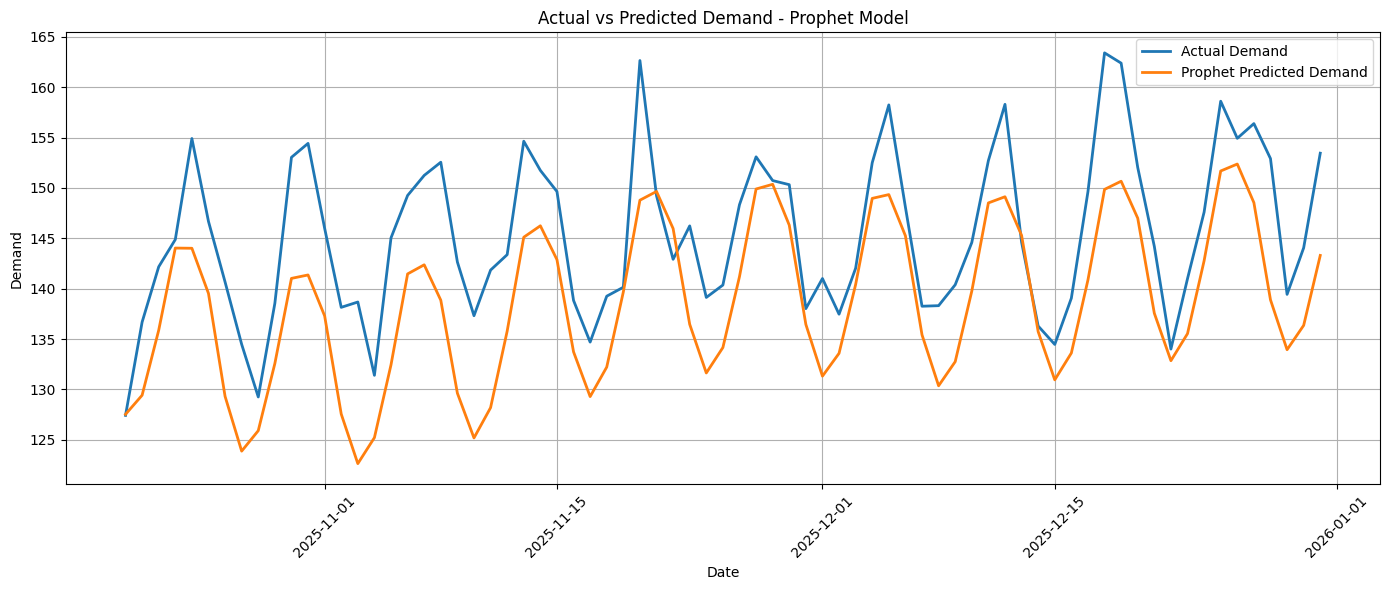

In [10]:

# Plot actual vs predicted demand

plt.figure(figsize=(14, 6))

plt.plot(
    results["Date"],
    results["Actual Demand"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    results["Date"],
    results["Predicted Demand"],
    label="Prophet Predicted Demand",
    linewidth=2
)

plt.title("Actual vs Predicted Demand - Prophet Model")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [11]:
# Check forecast and evaluation results

print("PROPHET FORECASTING SUMMARY")
print("===========================")

print("Total training records:", len(train_data))
print("Total testing records:", len(test_data))
print("Total predictions:", len(forecast))

print("\nEvaluation Metrics:")
for metric, value in metrics.items():
    print(f"{metric}: {value:.2f}")

print("\nProphet forecasting completed successfully!")

PROPHET FORECASTING SUMMARY
Total training records: 292
Total testing records: 73
Total predictions: 73

Evaluation Metrics:
MAE: 6.93
RMSE: 8.00
MAPE: 4.73
WAPE: 4.77
Forecast Bias: -6.81

Prophet forecasting completed successfully!
